# Relative abundance from TESSERA v1.1 embeddings

PREDICTS survey sites worldwide, using `TotalAbundance` from studies that started in 2000 or later. Features are the mean TESSERA v1.1 embedding (2025) over a 160 m window around each site, streamed from Source Cooperative.

The 128 embedding dimensions are reduced to 32 principal components, and a mixed-effects random forest (MERF) predicts log abundance from them with a random intercept per study. 20% of studies are held out entirely. Their intercept is unknown, so predictions use the fixed effects only, and the metric is Spearman ρ between predicted and observed abundance within each held-out study that has at least 5 sites.

In [1]:
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import zarr
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from scipy.ndimage import uniform_filter
from scipy.stats import spearmanr, ConstantInputWarning
from merf import MERF
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from geotessera.store import GeoTesseraZarr, zarr_store

logging.getLogger("geotessera").setLevel(logging.ERROR)
logging.getLogger("merf").setLevel(logging.WARNING)
warnings.simplefilter("ignore", ConstantInputWarning)
YEAR, SIZE_PX, FIRST_SURVEY, N_PCS, MIN_SCORE, SEED = 2025, 16, 2000, 32, 5, 0     # 16 px x 10 m = 160 m window
BANDS = [f"e{i}" for i in range(128)]

BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
DIVERGING = mpl.colors.LinearSegmentedColormap.from_list("div", [ORANGE, "#e1e0d9", BLUE])
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK, "xtick.color": GRAY, "ytick.color": GRAY,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e1e0d9", "axes.axisbelow": True, "figure.dpi": 120, "legend.frameon": False,
})

## Sites and embeddings

In [2]:
df = pd.read_csv("data/PREDICTs_coords.csv", index_col=0)
df["year"] = df.Sample_midpoint.str[:4].astype(int)
df = df[df.groupby("SSB").year.transform("min") >= FIRST_SURVEY]
sites = (df.groupby(["SSB", "Latitude", "Longitude"])
         .agg(abundance=("TotalAbundance", "mean"), taxon=("Study_common_taxon", "first"),
              land_use=("Predominant_land_use", "first"), year=("year", "first"))
         .reset_index())

gt = GeoTesseraZarr()  # TESSERA v1.1, Source Cooperative
print(gt.url, gt.model_version)
cache = Path(f"data/emb_v1.1_{YEAR}_{SIZE_PX}px.parquet")


def window_mean(r):
    try:
        patch, _, _ = gt.read_patch(r.Longitude, r.Latitude, year=YEAR, size_px=SIZE_PX)
        flat = patch.reshape(-1, 128)
        flat = flat[np.isfinite(flat).all(1)]
        return flat.mean(0) if len(flat) else np.full(128, np.nan)
    except Exception:
        return np.full(128, np.nan)


emb = pd.read_parquet(cache) if cache.exists() else pd.DataFrame(columns=["Latitude", "Longitude"] + BANDS, dtype=float)
todo = (sites[["Latitude", "Longitude"]].drop_duplicates()
        .merge(emb[["Latitude", "Longitude"]], how="left", indicator=True)
        .query("_merge == 'left_only'").drop(columns="_merge").reset_index(drop=True))
if len(todo):  # several minutes for ~18k locations on a fresh run
    with ThreadPoolExecutor(64) as ex:
        E = np.stack(list(ex.map(window_mean, todo.itertuples())))
    emb = pd.concat([emb, todo.join(pd.DataFrame(E, columns=BANDS))], ignore_index=True)
    emb.to_parquet(cache)

sites = sites.merge(emb, on=["Latitude", "Longitude"]).dropna(subset=BANDS).reset_index(drop=True)
sites["y"] = np.log1p(sites.abundance)
sites["y_rel"] = sites.y - sites.groupby("SSB").y.transform("mean")

test_idx = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEED).split(sites, groups=sites.SSB))[1]
sites["test"] = sites.index.isin(test_idx)
sites.groupby(sites.test.map({False: "train", True: "test"})).agg(
    sites=("SSB", "size"), studies=("SSB", "nunique"), taxa=("taxon", "nunique"),
    survey_years=("year", lambda x: f"{x.min()}-{x.max()}"))

https://data.source.coop/tessera/tessera/zarr/v1.1-dclimate https://geotessera.org/model/1.1


,sites,studies,taxa,survey_years
test,,,,
test,4618,888,54,2000-2017
train,19261,3548,71,2000-2018


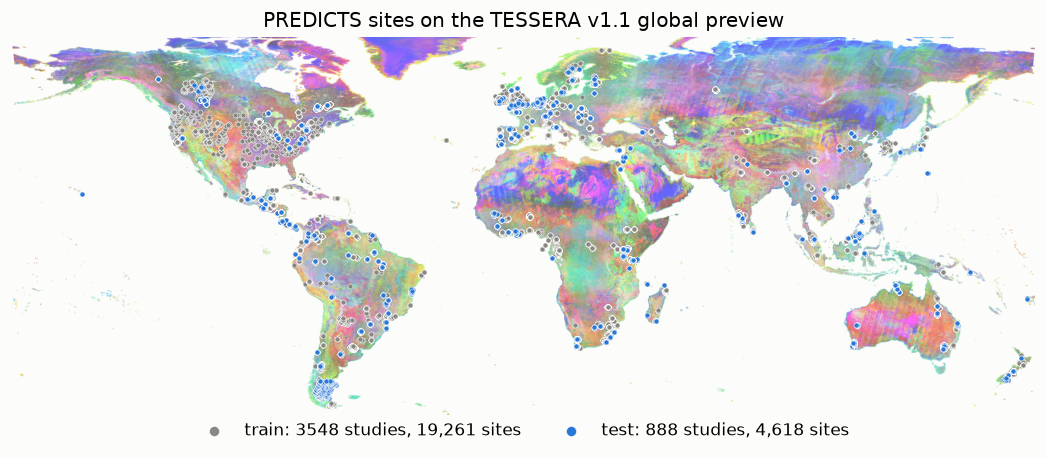

In [3]:
root = zarr.open_group(zarr_store(gt.url), mode="r")
world = root["global_rgb/9/rgb"][:]

fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow(world, extent=[-180, 180, -90, 90], alpha=0.6)
for test, c in [(False, GRAY), (True, BLUE)]:
    s = sites[sites.test == test]
    ax.scatter(s.Longitude, s.Latitude, s=9, c=c, edgecolors="white", linewidths=0.3,
               label=f"{'test' if test else 'train'}: {s.SSB.nunique()} studies, {len(s):,} sites")
ax.set(xlim=(-180, 180), ylim=(-58, 75), title="PREDICTS sites on the TESSERA v1.1 global preview")
ax.set_axis_off()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2, markerscale=2);

## Model

In [4]:
train = ~sites.test.values
pca = make_pipeline(StandardScaler(), PCA(N_PCS, random_state=SEED)).fit(sites.loc[train, BANDS].values)
X = pca.transform(sites[BANDS].values)
model = MERF(RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=1 / 3, n_jobs=-1, random_state=SEED),
             max_iterations=20)
model.fit(X[train], np.ones((train.sum(), 1)), pd.Series(sites.SSB.values[train]), sites.y.values[train])
sites["pred"] = model.trained_fe_model.predict(X)  # fixed effects only: held-out studies have no intercept
sites["pred_rel"] = sites.pred - sites.groupby("SSB").pred.transform("mean")
v_study, v_resid = float(model.D_hat_history[-1][0, 0]), float(model.sigma2_hat_history[-1])
print(f"study variance {v_study:.2f}, residual {v_resid:.2f}, ICC {v_study / (v_study + v_resid):.2f}")

study variance 9.15, residual 0.45, ICC 0.95


## Results

In [5]:
rho = (sites[sites.groupby("SSB").SSB.transform("size") >= MIN_SCORE].groupby("SSB").apply(lambda g: spearmanr(g.y, g.pred).statistic).dropna().rename("rho").to_frame()
       .join(sites.groupby("SSB").agg(test=("test", "first"), taxon=("taxon", "first"), n=("y", "size"),
                                      lon=("Longitude", "mean"), lat=("Latitude", "mean"))))


def summary(test):
    r, s = rho[rho.test == test].rho, sites[sites.test == test]
    boot = np.random.default_rng(SEED).choice(r, (4000, len(r))).mean(1)
    return {"studies": len(r), "mean within-study ρ": round(r.mean(), 3),
            "95% CI (bootstrap over studies)": f"[{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]",
            "studies with ρ > 0": f"{(r > 0).mean():.0%}",
            "within-study R²": round(1 - ((s.y_rel - s.pred_rel) ** 2).sum() / (s.y_rel ** 2).sum(), 3)}


pd.DataFrame({"train": summary(False), "test": summary(True)}).T

,studies,mean within-study ρ,95% CI (bootstrap over studies),studies with ρ > 0,within-study R²
train,748,0.638,"[0.615, 0.658]",96%,0.264
test,186,0.148,"[0.088, 0.205]",64%,-0.003


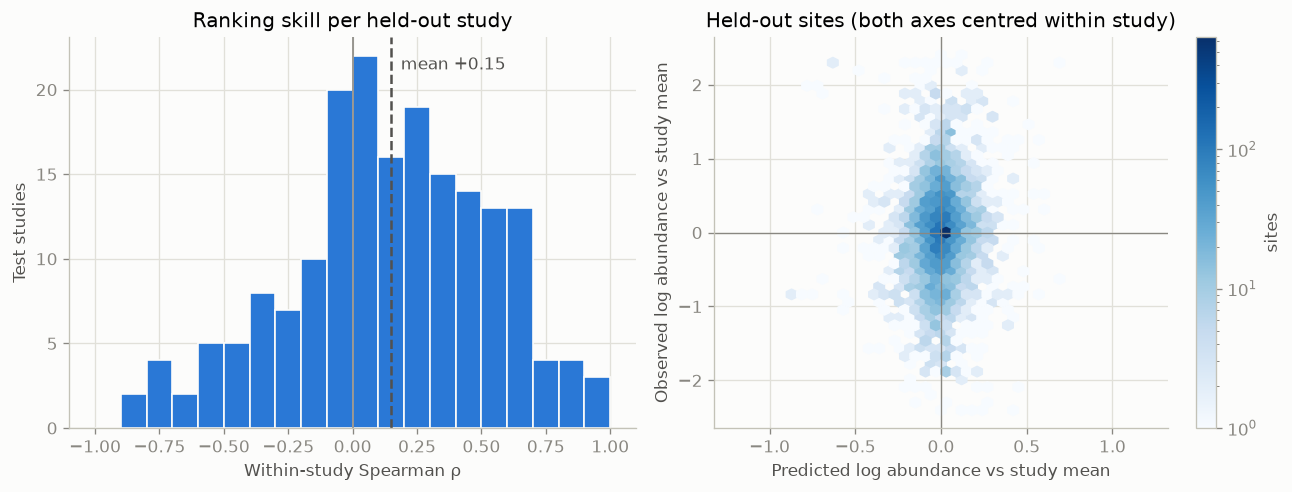

In [6]:
t, rt = sites[sites.test], rho[rho.test]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.hist(rt.rho, bins=np.linspace(-1, 1, 21), color=BLUE, edgecolor="#fcfcfb")
ax1.axvline(0, color=GRAY, lw=1)
ax1.axvline(rt.rho.mean(), color=INK, lw=1.5, ls="--")
ax1.text(rt.rho.mean(), ax1.get_ylim()[1] * 0.95, f"  mean {rt.rho.mean():+.2f}", color=INK, va="top")
ax1.set(xlabel="Within-study Spearman ρ", ylabel="Test studies", title="Ranking skill per held-out study")

lim = np.percentile(np.abs(t.y_rel), 99)
hb = ax2.hexbin(t.pred_rel, t.y_rel, gridsize=40, cmap="Blues", mincnt=1, bins="log",
                extent=(-lim / 2, lim / 2, -lim, lim))
ax2.axhline(0, color=GRAY, lw=0.8); ax2.axvline(0, color=GRAY, lw=0.8)
ax2.set(xlabel="Predicted log abundance vs study mean", ylabel="Observed log abundance vs study mean",
        title="Held-out sites (both axes centred within study)")
fig.colorbar(hb, ax=ax2, label="sites")
fig.tight_layout()

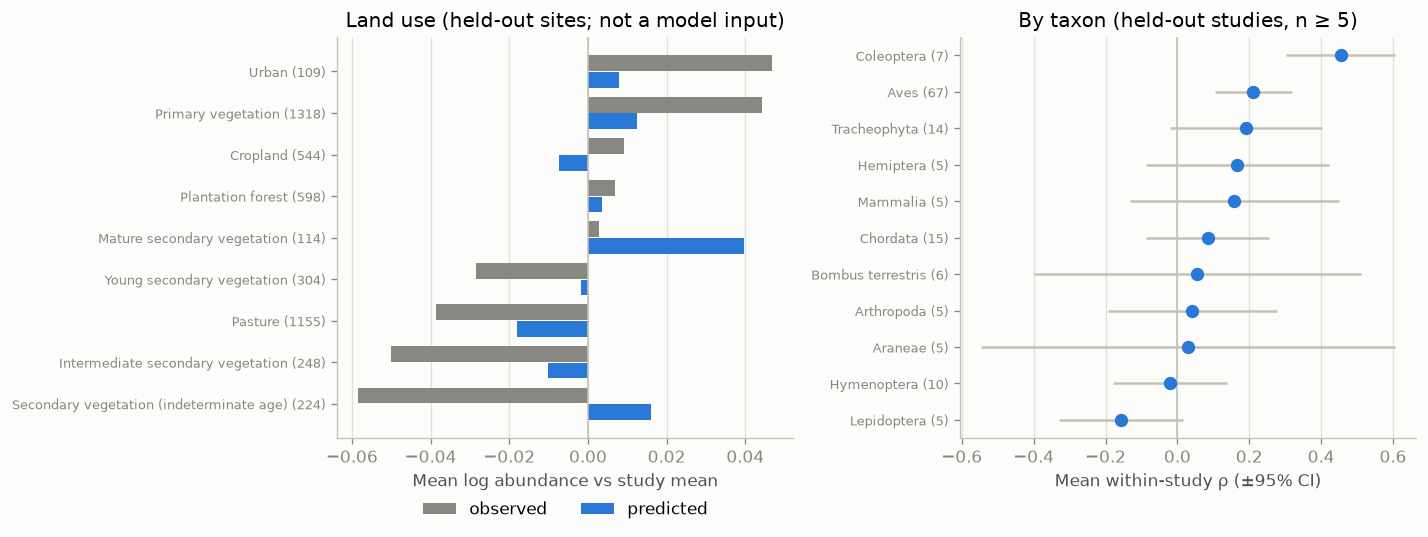

In [7]:
lu = (t.groupby("land_use")[["y_rel", "pred_rel"]].mean().join(t.land_use.value_counts())
      .query("count >= 100").sort_values("y_rel"))
taxa = (rt.groupby("taxon").rho.agg(["mean", "sem", "size"])
        .query("size >= 5").sort_values("mean"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
yy = np.arange(len(lu))
ax1.barh(yy + 0.2, lu.y_rel, height=0.38, color=GRAY, label="observed")
ax1.barh(yy - 0.2, lu.pred_rel, height=0.38, color=BLUE, label="predicted")
ax1.axvline(0, color="#c3c2b7", lw=1)
ax1.set_yticks(yy, [f"{k} ({n})" for k, n in zip(lu.index, lu["count"])], fontsize=8)
ax1.set(xlabel="Mean log abundance vs study mean", title="Land use (held-out sites; not a model input)")
ax1.grid(axis="y", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

yy = np.arange(len(taxa))
ax2.errorbar(taxa["mean"], yy, xerr=1.96 * taxa["sem"], fmt="o", color=BLUE, ecolor="#c3c2b7", ms=7)
ax2.axvline(0, color="#c3c2b7", lw=1)
ax2.set_yticks(yy, [f"{k} ({n})" for k, n in zip(taxa.index, taxa["size"])], fontsize=8)
ax2.set(xlabel="Mean within-study ρ (±95% CI)", title="By taxon (held-out studies, n ≥ 5)")
ax2.grid(axis="y", visible=False)
fig.tight_layout()

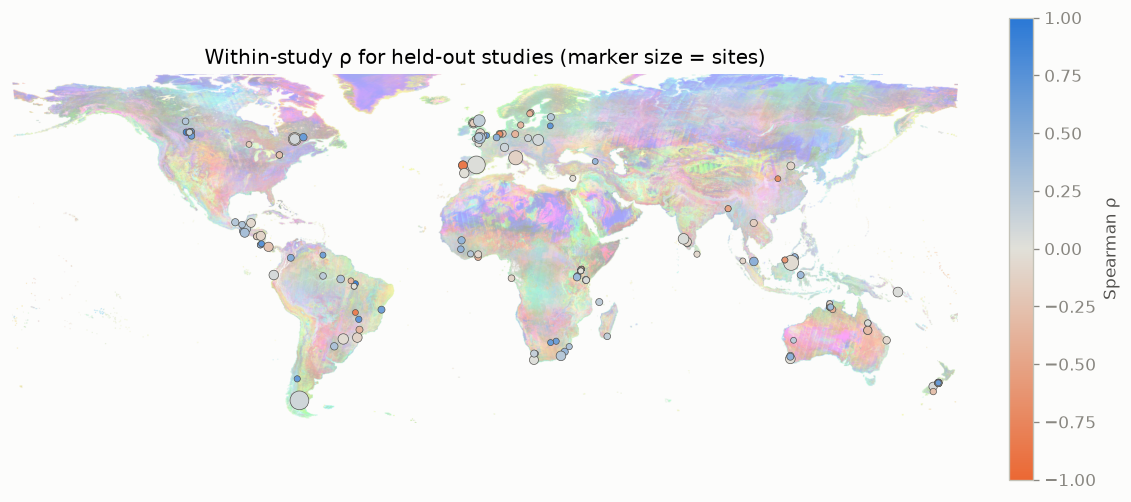

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow(world, extent=[-180, 180, -90, 90], alpha=0.35)
sc = ax.scatter(rt.lon, rt.lat, c=rt.rho, cmap=DIVERGING, vmin=-1, vmax=1, s=10 + rt.n / 2,
                edgecolors=INK, linewidths=0.4)
ax.set(xlim=(-180, 180), ylim=(-58, 75), title="Within-study ρ for held-out studies (marker size = sites)")
ax.set_axis_off()
fig.colorbar(sc, ax=ax, fraction=0.025, label="Spearman ρ");

## Prediction map

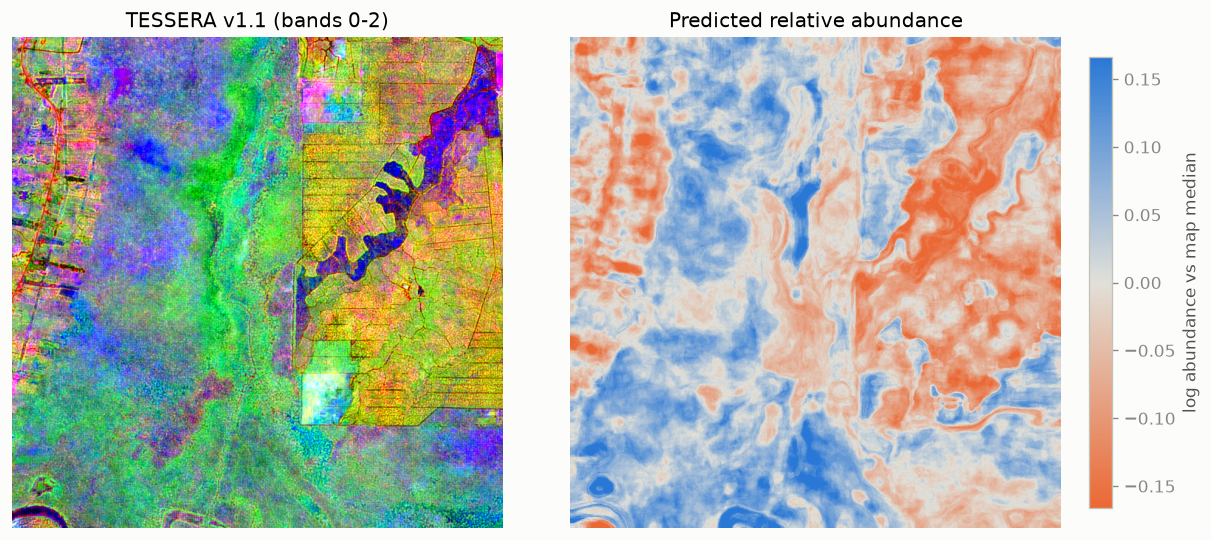

In [9]:
BBOX = (117.95, 5.42, 118.01, 5.48)  # forest / oil-palm edge, Sabah, Borneo

emb_map, _, _ = gt.read_region(BBOX, year=YEAR)
win = uniform_filter(emb_map, size=(SIZE_PX, SIZE_PX, 1))  # same 160 m window mean as training
p = model.trained_fe_model.predict(pca.transform(win.reshape(-1, 128))).reshape(win.shape[:2])
p -= np.nanmedian(p)
rgb = emb_map[..., :3]
lo, hi = np.nanpercentile(rgb, [2, 98], axis=(0, 1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.6))
ax1.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1))
ax1.set_title("TESSERA v1.1 (bands 0-2)")
v = np.nanpercentile(np.abs(p), 98)
im = ax2.imshow(p, cmap=DIVERGING, vmin=-v, vmax=v)
ax2.set_title("Predicted relative abundance")
fig.colorbar(im, ax=ax2, fraction=0.04, label="log abundance vs map median")
for ax in (ax1, ax2):
    ax.set_axis_off()
fig.tight_layout()

## Caveats

The surveys were done between 2000 and 2018 but the embeddings are from 2025, so any land-cover change in between is unmodelled noise. A new study's overall abundance level can't be predicted, so all predictions are relative to the study mean. Studies are scored as independent, but some share authors and regions.